# Notebook 09 — XAI: Transformer Attention Weight Analysis

**Method:** Attention weight extraction — built-in Transformer XAI  
**Applied to:** Transformer only  
**Dataset:** NASA CMAPSS — FD001

### What attention weights show
Attention weights answer a different question from SHAP and IG:
- SHAP / IG : which **sensors** at which **cycles** drove the prediction?
- Attention : which **cycles** did the model find most relevant to each other?

Together the three methods give the complete explanation:
  - Attention: the model focused on cycles 25–30
  - SHAP/IG:   in those cycles, s_11 and s_4 drove the prediction


## 0 · Imports

In [1]:
import sys
from pathlib import Path
PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils.config import DATA_PROC, OUT_MODELS, OUT_FIGURES
from src.models.transformer import TransformerModel
from src.explainability.attention_viz import AttentionVisualiser

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.facecolor': 'white'})

SUBSET  = 'FD001'
DEVICE  = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SENSORS = ['s_2','s_3','s_4','s_7','s_8','s_9','s_11',
           's_12','s_13','s_14','s_15','s_17','s_20','s_21']
print(f'Device: {DEVICE}')

Device: cpu


## 1 · Load Transformer and test data

In [3]:
proc   = DATA_PROC / SUBSET
X_test = np.load(proc / 'X_test.npy')
y_test = np.load(proc / 'y_test.npy')

model = TransformerModel()
ckpt  = OUT_MODELS / f'transformer_{SUBSET}_best.pt'
model.load_state_dict(torch.load(ckpt, map_location=DEVICE, weights_only=True))
model.eval()
model = model.to(DEVICE)

viz = AttentionVisualiser(model, DEVICE)

# Select engines
target_ruls   = [110, 60, 15]
engine_ids    = [int(np.argmin(np.abs(y_test - t))) for t in target_ruls]
actual_ruls   = [y_test[i] for i in engine_ids]
engine_labels = ['Healthy', 'Mid-life', 'Near-failure']

print('Transformer loaded ')
for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    print(f'  {label:<15} idx={eid}  RUL={rul:.0f}')

Transformer loaded 
  Healthy         idx=8  RUL=111
  Mid-life        idx=42  RUL=59
  Near-failure    idx=55  RUL=15


## 2 · Attention maps — all 3 layers, all 3 engine types


── Healthy (actual RUL=111, pred=118.5) ──
Saved -> C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_FD001_healthy.png


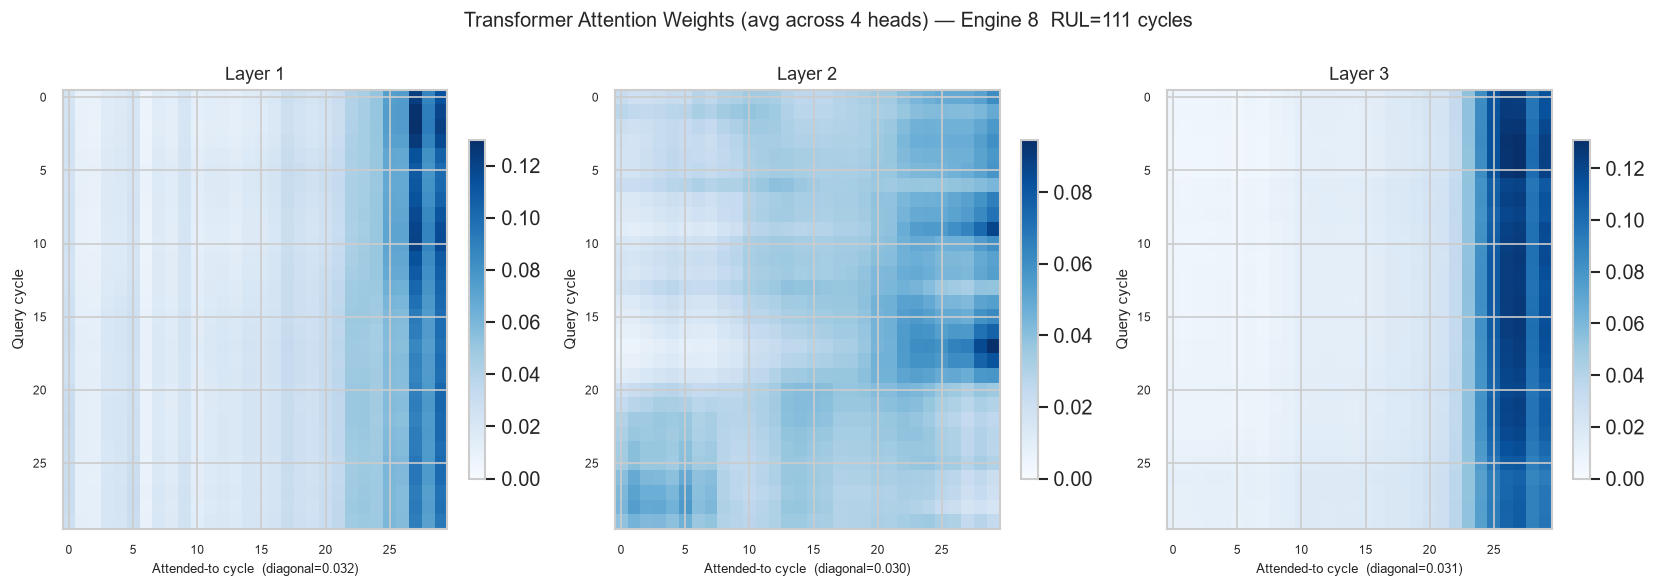


── Mid-life (actual RUL=59, pred=58.8) ──
Saved -> C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_FD001_mid_life.png


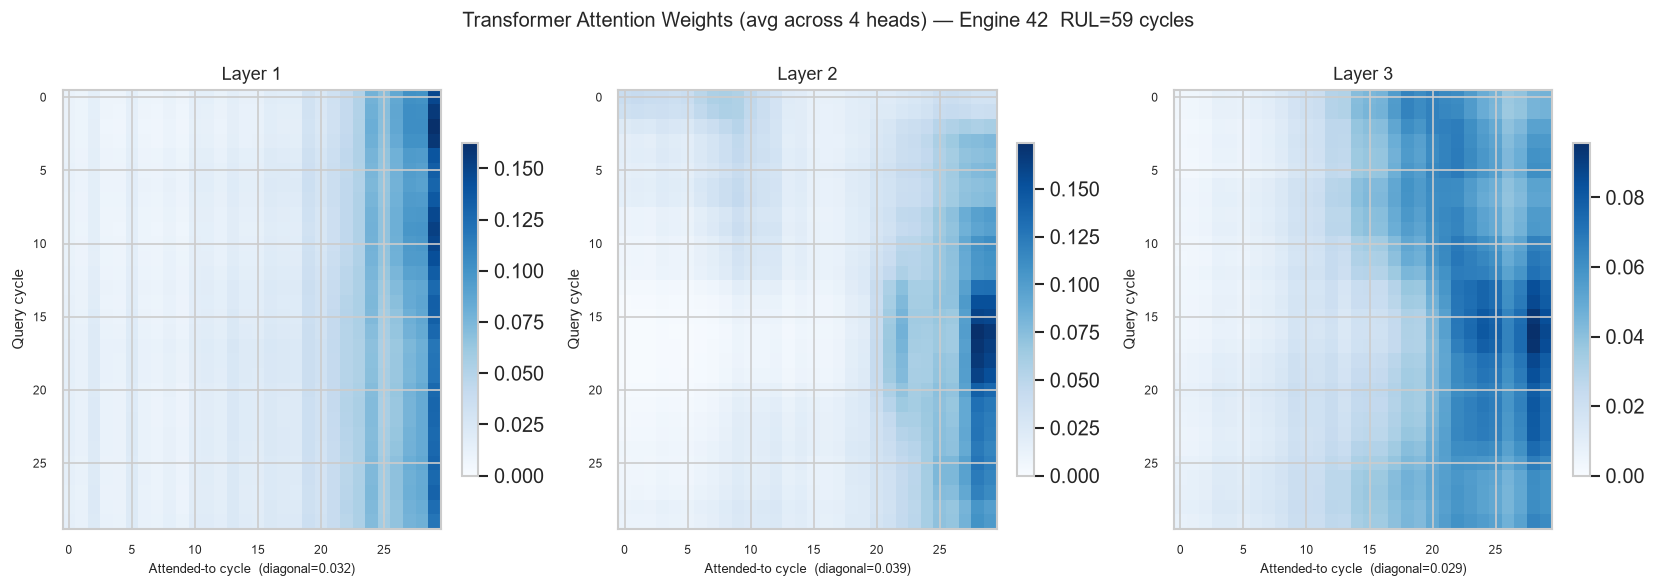


── Near-failure (actual RUL=15, pred=18.0) ──
Saved -> C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_FD001_near_failure.png


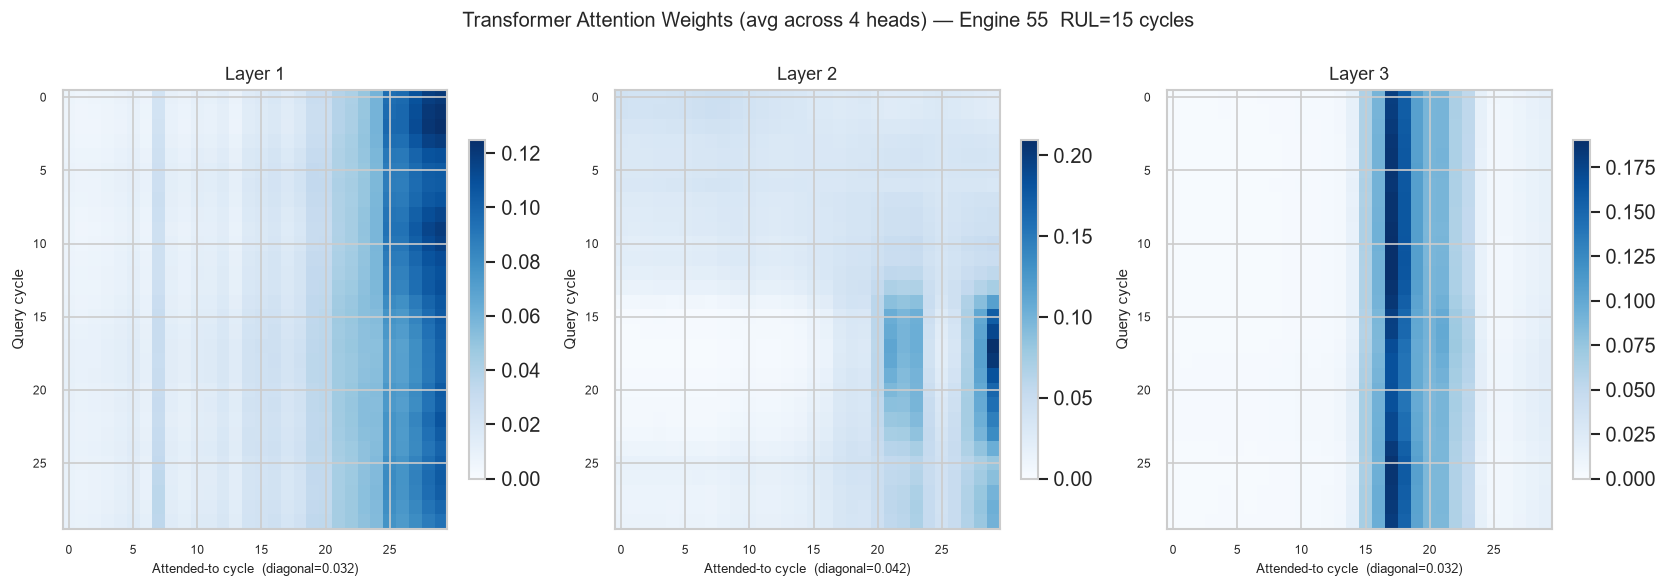

In [4]:
for label, eid, rul in zip(engine_labels, engine_ids, actual_ruls):
    window = torch.tensor(X_test[eid:eid+1], dtype=torch.float32)

    with torch.no_grad():
        pred = model(window.to(DEVICE)).item()

    print(f'\n── {label} (actual RUL={rul:.0f}, pred={pred:.1f}) ──')

    viz.plot_attention(
        window,
        rul       = rul,
        engine_id = eid,
        save_path = OUT_FIGURES / f'attn_{SUBSET}_{label.lower().replace("-","_")}.png',
    )

## 3 · Per-head analysis — all 4 heads in layer 3 (deepest layer)

Showing all 4 attention heads from the deepest encoder layer (layer 3):
Each head has learned a different type of cycle-to-cycle relationship.
Saved -> C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_heads_layer1_FD001_near_failure.png


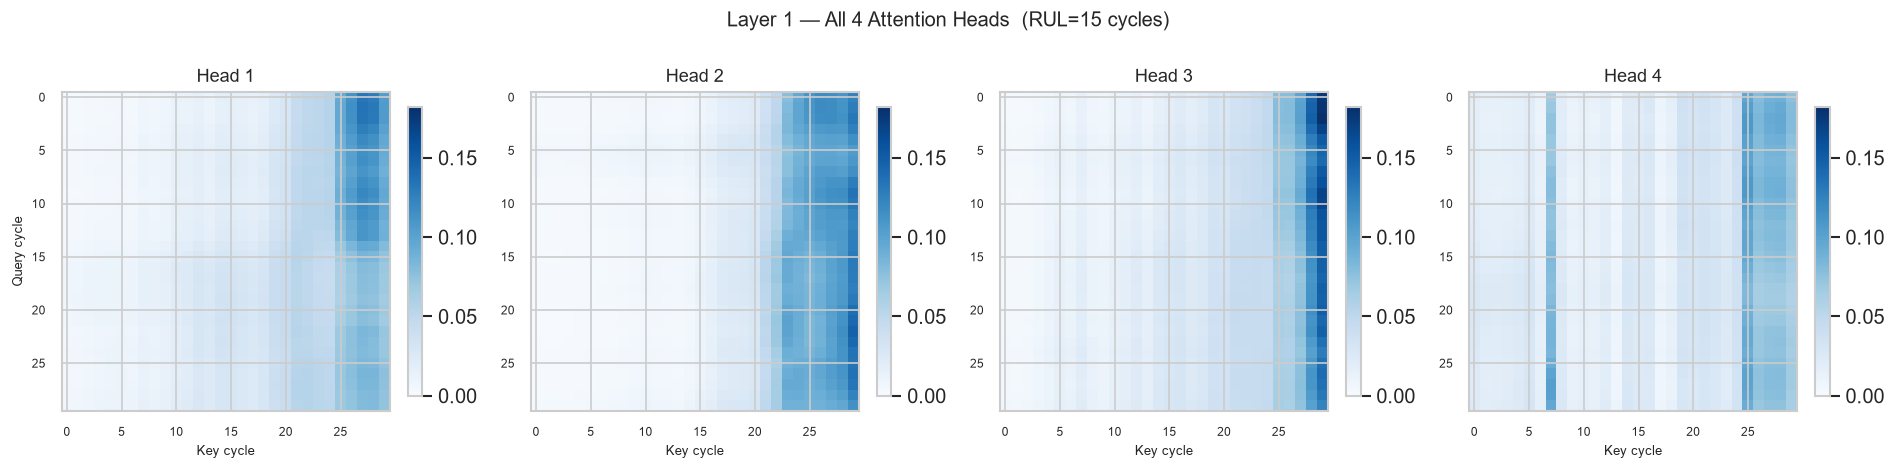

Saved -> C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_heads_layer2_FD001_near_failure.png


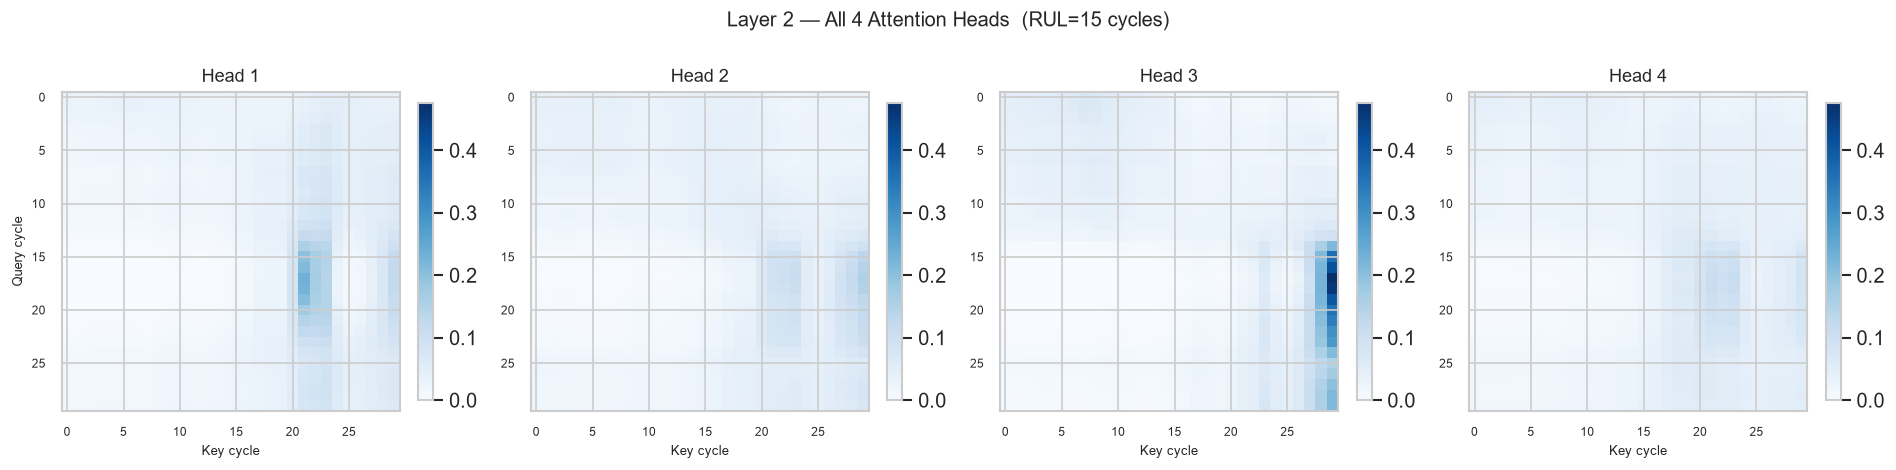

Saved -> C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_heads_layer3_FD001_near_failure.png


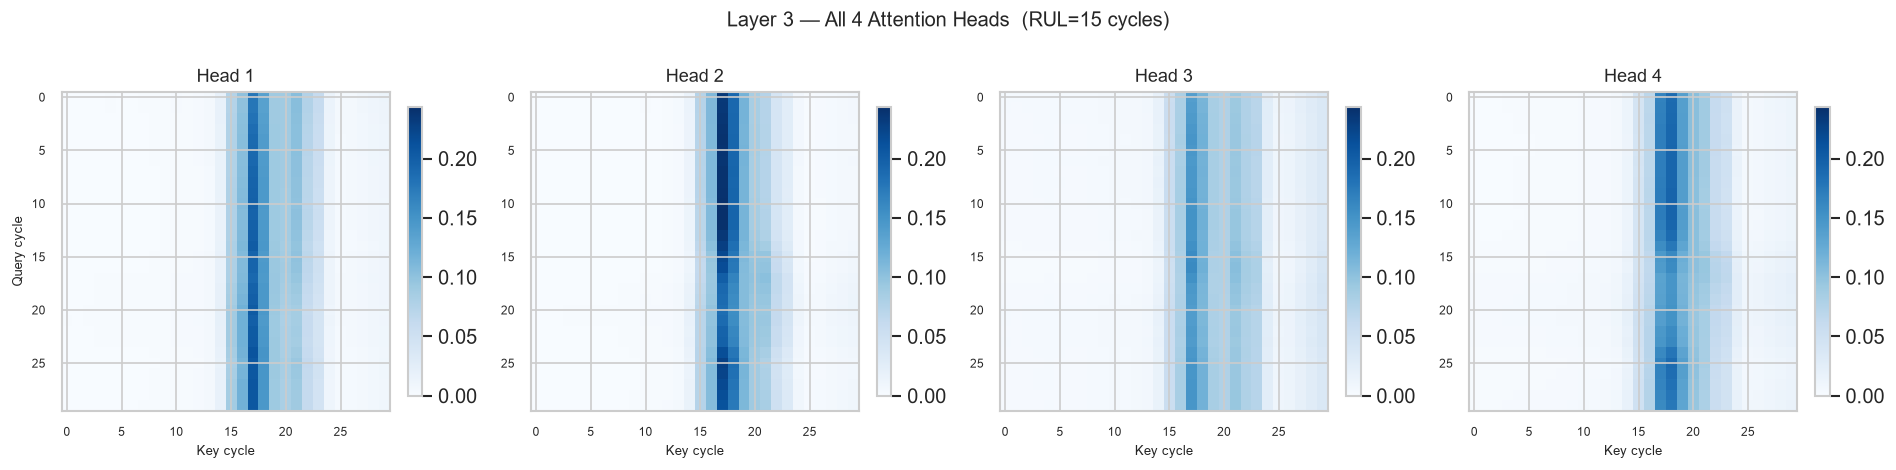

In [5]:
# Focus on near-failure engine — most interesting for maintenance
eid_fail = engine_ids[2]
window   = torch.tensor(X_test[eid_fail:eid_fail+1], dtype=torch.float32)

print('Showing all 4 attention heads from the deepest encoder layer (layer 3):')
print('Each head has learned a different type of cycle-to-cycle relationship.')

for layer_idx in [0, 1, 2]:
    viz.plot_head_comparison(
        window,
        layer_idx = layer_idx,
        rul       = actual_ruls[2],
        save_path = OUT_FIGURES / f'attn_heads_layer{layer_idx+1}_{SUBSET}_near_failure.png',
    )

## 4 · Attention vs sensor signal — does the model look where drift is steepest?


s_11 — HPC pressure — expected to FALL near failure
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_vs_signal_s_11_FD001.png


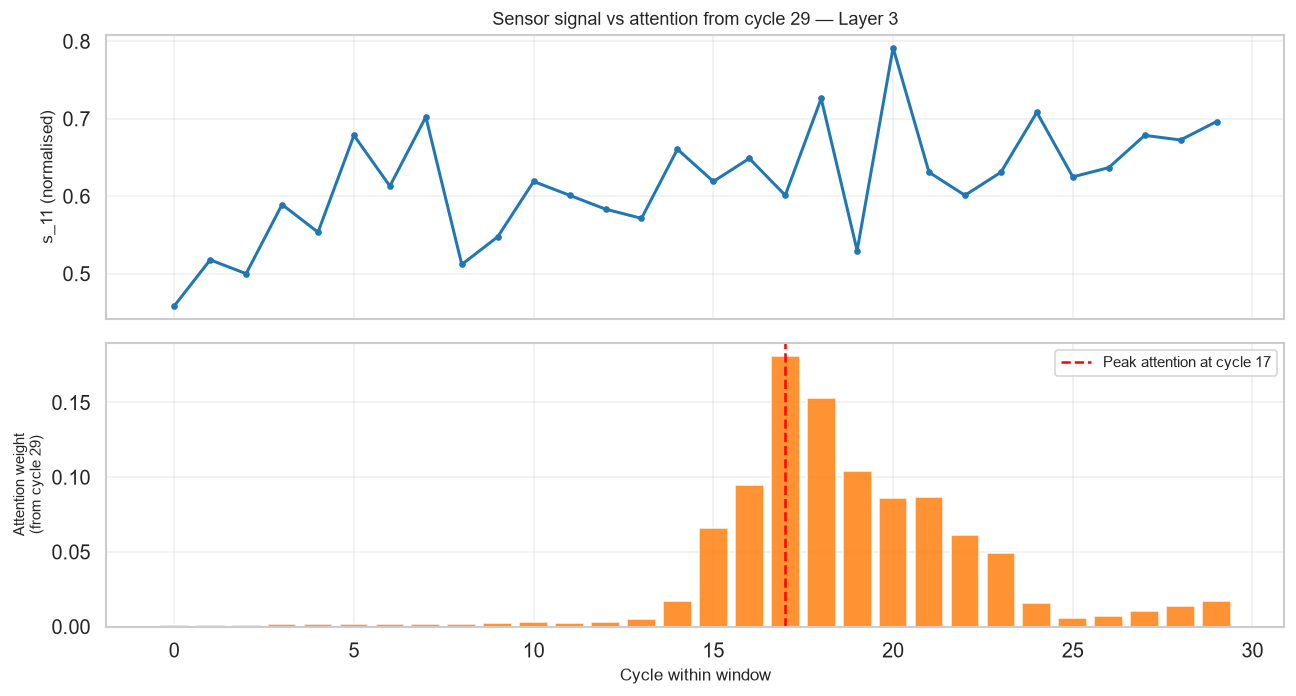


s_4 — Exhaust temp — expected to RISE near failure
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_vs_signal_s_4_FD001.png


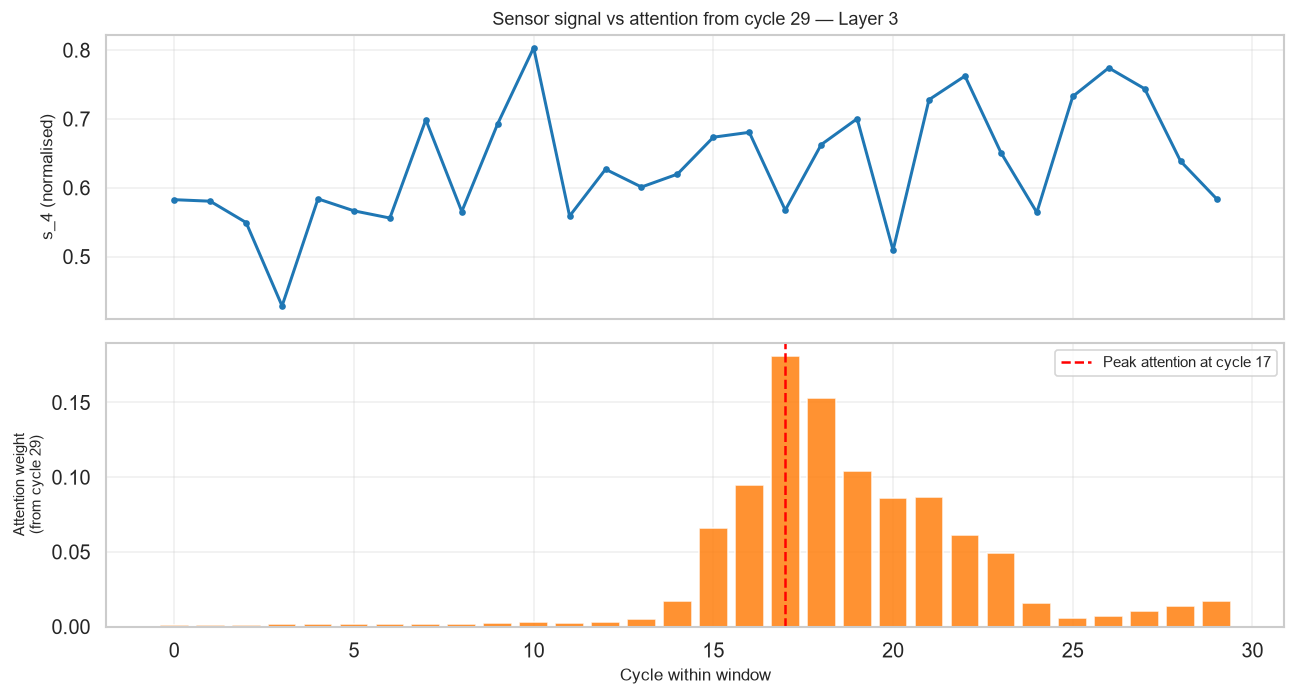


s_12 — Fuel flow — expected to RISE near failure
Saved → C:\Users\rumma\OneDrive\Desktop\Dissertation\xpdm_starter\outputs\figures\attn_vs_signal_s_12_FD001.png


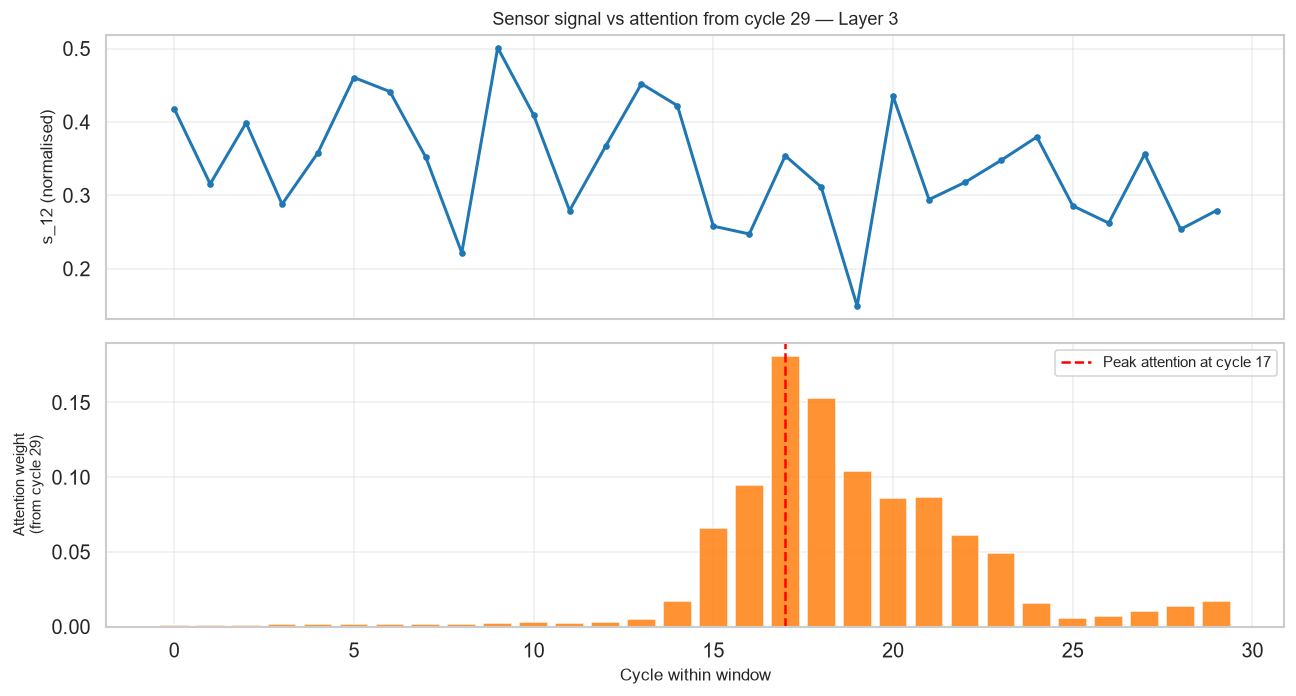

In [6]:
# For each key sensor, plot the signal alongside attention from cycle 29
eid_fail   = engine_ids[2]
window     = torch.tensor(X_test[eid_fail:eid_fail+1], dtype=torch.float32)
sensor_arr = X_test[eid_fail]   # (30, 14) — actual sensor readings

# Focus on top 3 EDA sensors
focus_sensors = [
    (SENSORS.index('s_11'), 's_11', 'HPC pressure — expected to FALL near failure'),
    (SENSORS.index('s_4'),  's_4',  'Exhaust temp — expected to RISE near failure'),
    (SENSORS.index('s_12'), 's_12', 'Fuel flow — expected to RISE near failure'),
]

for s_idx, s_name, s_desc in focus_sensors:
    print(f'\n{s_name} — {s_desc}')
    viz.plot_attention_vs_degradation(
        window,
        sensor_array = sensor_arr,
        sensor_idx   = s_idx,
        sensor_name  = s_name,
        layer_idx    = 2,   # deepest layer
        save_path    = OUT_FIGURES / f'attn_vs_signal_{s_name}_{SUBSET}.png',
    )

## 5 · Attention summary statistics — all 100 test engines

Computing attention summaries for all 100 test engines


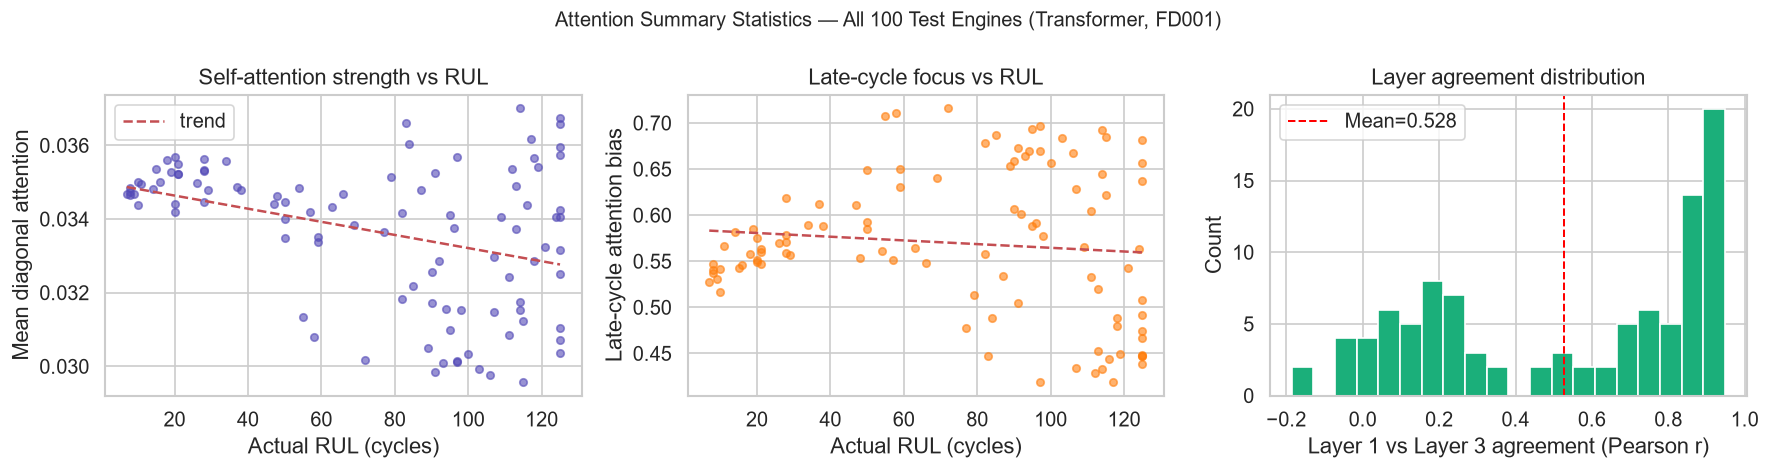


Correlation between attention patterns and RUL:
  Self-attention diagonal vs RUL : r=-0.370  p=0.0002
  Late-cycle bias vs RUL         : r=-0.103  p=0.3085
  Mean layer agreement           : 0.528


In [8]:
print('Computing attention summaries for all 100 test engines')

summaries = []
for i in range(len(X_test)):
    window = torch.tensor(X_test[i:i+1], dtype=torch.float32)
    s = viz.attention_summary(window)
    s['rul'] = float(y_test[i])
    summaries.append(s)

diagonals  = np.array([s['mean_diagonal']    for s in summaries])
late_biases = np.array([s['late_bias']        for s in summaries])
agreements  = np.array([s['layer_agreement']  for s in summaries])
ruls        = np.array([s['rul']              for s in summaries])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Diagonal vs RUL — does self-attention increase as engine degrades?
axes[0].scatter(ruls, diagonals, alpha=0.6, s=20, color='#534AB7')
axes[0].set_xlabel('Actual RUL (cycles)')
axes[0].set_ylabel('Mean diagonal attention')
axes[0].set_title('Self-attention strength vs RUL')
z = np.polyfit(ruls, diagonals, 1)
axes[0].plot(np.sort(ruls), np.poly1d(z)(np.sort(ruls)),
             'r--', linewidth=1.5, label=f'trend')
axes[0].legend()

# Late bias vs RUL — does model focus more on recent cycles when RUL is low?
axes[1].scatter(ruls, late_biases, alpha=0.6, s=20, color='#ff7f0e')
axes[1].set_xlabel('Actual RUL (cycles)')
axes[1].set_ylabel('Late-cycle attention bias')
axes[1].set_title('Late-cycle focus vs RUL')
z2 = np.polyfit(ruls, late_biases, 1)
axes[1].plot(np.sort(ruls), np.poly1d(z2)(np.sort(ruls)),
             'r--', linewidth=1.5)

# Layer agreement distribution
axes[2].hist(agreements, bins=20, color='#1baf7a', edgecolor='white')
axes[2].set_xlabel('Layer 1 vs Layer 3 agreement (Pearson r)')
axes[2].set_ylabel('Count')
axes[2].set_title('Layer agreement distribution')
axes[2].axvline(agreements.mean(), color='red', linestyle='--',
                linewidth=1.2, label=f'Mean={agreements.mean():.3f}')
axes[2].legend()

fig.suptitle('Attention Summary Statistics — All 100 Test Engines (Transformer, FD001)',
             fontsize=12)
plt.tight_layout()
plt.savefig(OUT_FIGURES / f'attn_summary_stats_{SUBSET}.png', bbox_inches='tight')
plt.show()

# Correlation between attention stats and RUL
from scipy.stats import pearsonr
r_diag, p_diag = pearsonr(ruls, diagonals)
r_late, p_late = pearsonr(ruls, late_biases)
print(f'\nCorrelation between attention patterns and RUL:')
print(f'  Self-attention diagonal vs RUL : r={r_diag:.3f}  p={p_diag:.4f}')
print(f'  Late-cycle bias vs RUL         : r={r_late:.3f}  p={p_late:.4f}')
print(f'  Mean layer agreement           : {agreements.mean():.3f}')

## 6 · Cross-subset comparison — FD001 vs FD003 attention patterns

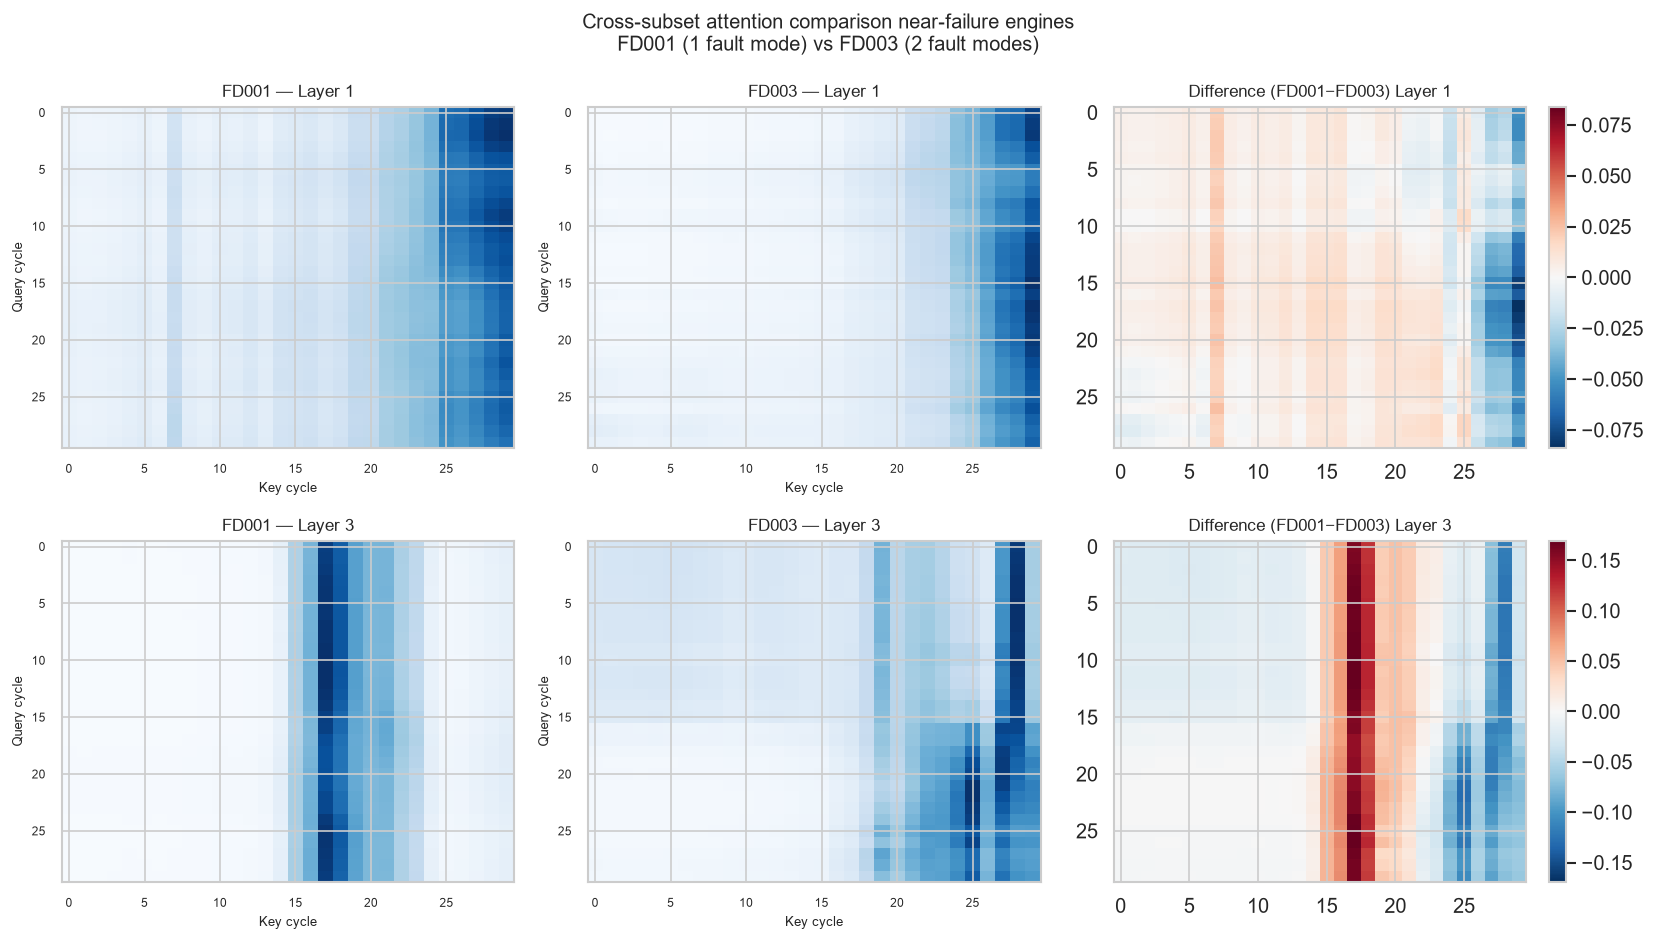

Cross-subset comparison complete.
Look for differences in attention patterns FD003 may show more dispersed
attention due to mixed fault modes confusing the temporal focus.


In [12]:
# Load FD003 model and test data
proc_fd003   = DATA_PROC / 'FD003'
X_test_fd003 = np.load(proc_fd003 / 'X_test.npy')
y_test_fd003 = np.load(proc_fd003 / 'y_test.npy')

fd003_model = TransformerModel()
ckpt_fd003  = OUT_MODELS / 'transformer_FD003_best.pt'

if ckpt_fd003.exists():
    fd003_model.load_state_dict(
        torch.load(ckpt_fd003, map_location=DEVICE, weights_only=True))
    fd003_model.eval()
    fd003_viz = AttentionVisualiser(fd003_model.to(DEVICE), DEVICE)

    # Compare near-failure attention patterns
    eid_fd001 = engine_ids[2]
    eid_fd003 = int(np.argmin(np.abs(y_test_fd003 - 15)))

    w_fd001 = torch.tensor(X_test[eid_fd001:eid_fd001+1], dtype=torch.float32)
    w_fd003 = torch.tensor(X_test_fd003[eid_fd003:eid_fd003+1], dtype=torch.float32)

    wts_fd001 = viz.get_weights(w_fd001)
    wts_fd003 = fd003_viz.get_weights(w_fd003)

    fig, axes = plt.subplots(2, 3, figsize=(14, 8))

    for col, (wts, label, rul) in enumerate([
        (wts_fd001, 'FD001', y_test[eid_fd001]),
        (wts_fd003, 'FD003', y_test_fd003[eid_fd003]),
    ]):
        pass

    for row, layer_idx in enumerate([0, 2]):
        for col, (wts, subset_name) in enumerate([(wts_fd001,'FD001'),(wts_fd003,'FD003')]):
            ax  = axes[row][col]
            avg = wts[layer_idx].mean(axis=0)   # avg across 4 heads
            ax.imshow(avg, cmap='Blues', aspect='auto', vmin=0)
            if col == 1:   # after plotting both subsets
                ax_diff = axes[row][2]
                diff = wts_fd001[layer_idx].mean(axis=0) - wts_fd003[layer_idx].mean(axis=0)
                im_diff = ax_diff.imshow(diff, cmap='RdBu_r', aspect='auto', vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
                ax_diff.set_title(f'Difference (FD001−FD003) Layer {layer_idx+1}', fontsize=10)
                plt.colorbar(im_diff, ax=ax_diff, fraction=0.04)
            ax.set_title(f'{subset_name} — Layer {layer_idx+1}', fontsize=10)
            ax.set_xlabel('Key cycle', fontsize=8)
            ax.set_ylabel('Query cycle', fontsize=8)
            ax.tick_params(labelsize=7)

    fig.suptitle('Cross-subset attention comparison near-failure engines\n'
                 'FD001 (1 fault mode) vs FD003 (2 fault modes)', fontsize=12)
    plt.tight_layout()
    plt.savefig(OUT_FIGURES / 'attn_cross_subset_FD001_FD003.png', bbox_inches='tight')
    plt.show()
    print('Cross-subset comparison complete.')
    print('Look for differences in attention patterns FD003 may show more dispersed')
    print('attention due to mixed fault modes confusing the temporal focus.')
else:
    print('FD003 Transformer checkpoint not found.')
    print('Run: python -m src.utils.trainer --model transformer --subset FD003')